# MLP

implementation

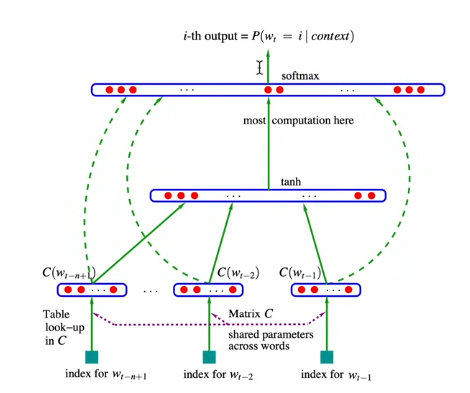


We have a vocab of 17k words, each will be embedded in 30 dimensions, so our lookup table C is 17000x30

Pass in 3 words as inputs: their index goes to the lookup table, and returns the 3 embeddings of each length 30, so 90 input neurons

This goes to a hidden layer, the number of neurons is a hyperparameter to tune, with a tanh activation function (do we have biases?)

Finally from the hidden layer, we go to an output layer of 17000 neurons, one for each possible word, and we use softmax to return the probability

In [1]:
# how I think this will go for character based model
# create an embedding matrix: 27xn where n is any number of dimensions we want to choose: more = more complexity. This will be randomly initialised, and can be tuned using gradient descent
# set up the input layer, to be num_chars x n neurons after we do the mapping lookup
# set up a hidden layer, with number of num_hidden_neurons to be parameterised, and use tanh activation
# set up output layer of 27 neurons with softmax to return probabilities
# configure ave neg log likelihood loss function
# run backpropagation
# gradient descent and repeat 


In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [3]:
# bring in data
words = open('names.txt', 'r').read().splitlines()

In [4]:
# character indexes etc
chars = sorted(list(set(''.join(words))))
s_to_i = {s: i+1 for i, s in enumerate(chars)}
s_to_i['.'] = 0
i_to_s = {i:s for s, i in s_to_i.items()}

In [5]:
# build our input and output datasets - here we will use 3 input characters to predict the 4th

block_size = 3
X, Y = [], []

for w in words[:5]:
    # print(w)
    context = [0] * block_size # init the 3 full stops (index 0)
    for ch in w+'.': # loop through each letter (append a full stop so we know when the string ends)
        ix = s_to_i[ch] # get index of letter
        X.append(context) # add input list to full X list
        Y.append(ix) # add output char to y list
        # print(''.join((i_to_s[i] for i in context)), '--->', i_to_s[ix])
        context = context[1:] + [ix] # chop off the first context, and add new character at end to form new context for next letter

X = torch.tensor(X)
Y = torch.tensor(Y)


In [6]:
# create our embedding matrix
C = torch.randn((27,2)) # start with 2 dimensions to represent each character

In [7]:
# based on the above logic, we can quickly translate our X input indexes into their respective embeddings with the below
# this is our embedding matrix which we will pass into our next
emb = C[X]

emb # its n (number of 3char datapoints) x 3 (embedding vector for each character) x 2 (scalar for each embedding dimension)

tensor([[[ 1.5390, -1.4475],
         [ 1.5390, -1.4475],
         [ 1.5390, -1.4475]],

        [[ 1.5390, -1.4475],
         [ 1.5390, -1.4475],
         [ 0.8055, -0.2439]],

        [[ 1.5390, -1.4475],
         [ 0.8055, -0.2439],
         [-0.6488,  1.4923]],

        [[ 0.8055, -0.2439],
         [-0.6488,  1.4923],
         [-0.6488,  1.4923]],

        [[-0.6488,  1.4923],
         [-0.6488,  1.4923],
         [-1.3351, -2.1185]],

        [[ 1.5390, -1.4475],
         [ 1.5390, -1.4475],
         [ 1.5390, -1.4475]],

        [[ 1.5390, -1.4475],
         [ 1.5390, -1.4475],
         [-0.5341, -1.0224]],

        [[ 1.5390, -1.4475],
         [-0.5341, -1.0224],
         [ 0.2338, -1.0916]],

        [[-0.5341, -1.0224],
         [ 0.2338, -1.0916],
         [ 0.3294,  1.1083]],

        [[ 0.2338, -1.0916],
         [ 0.3294,  1.1083],
         [-1.4637,  1.7212]],

        [[ 0.3294,  1.1083],
         [-1.4637,  1.7212],
         [ 0.3294,  1.1083]],

        [[-1.4637,  1

In [8]:
# now lets create the hidden layer

# weights from input to first layer - 6xn where 6 is the 3 characters x 2 dimension embedding
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [9]:
# we cant jump into matrix multiplication yet a (32, 3, 2) @ (6, 100) wont work, we need to compress the embedding matrix to be 32 x 6, concatenating the embedding vectors in the second dimension
#emb.view(32, 6) # easily done with the view function - as long as the params multiply to the same as the input matrix 

# we can get our first hidden layer now with the following matrix multiplication
raw_hidden = emb.view(-1, 6) @ W1 + b1 # here we use -1 which allows pytorch to infer the required shape, so we dont hardcode the length of our dataset, then mat mul with our weights and add biases
hidden = torch.tanh(raw_hidden) # then we apply our activation function to squeeze between -1 and 1
hidden.shape

torch.Size([32, 100])

In [10]:
# now lets get output layer
W2 = torch.randn((100, 27)) # 100 neurons in hidden, 27 in output
b2 = torch.randn(27)

logits = hidden @ W2 + b2 # multiply the hidden activations with the weights and then add the biases to get the raw logits
counts = logits.exp()
probs = counts / counts.sum(1, keepdim=True)
# implement the softmax

In [11]:
# now that we have our probabilities, lets get the loss function (negative average log likelihood)
loss = -probs[torch.arange(Y.nelement()), Y].log().mean()
loss

tensor(16.9302)

# Bringing it all together

In [12]:
# now lets create a training loop - start with initial parameters
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 2), generator=g, requires_grad=True) # embedding matrix

# initialise first hidden layer
W1 = torch.randn((6, 100), generator=g, requires_grad=True)
b1 = torch.randn(100, generator=g, requires_grad=True)
# initialise connections to output layer
W2 = torch.randn((100, 27), generator=g, requires_grad=True)
b2 = torch.randn(27, generator=g, requires_grad=True)
params = [C, W1, b1, W2, b2]

sum(p.nelement() for p in params) # full sum, we have 3481

3481

In [13]:
# now
emb = C[X] # create the embedding vectors for all our our X inputs

# pass thru the first layer - reshape to be numX x 6 matrix, multiply weights, add biases and then take tanh
hidden_activation = torch.tanh(emb.view(-1, 6) @ W1 + b1)

# pass to output layer
logits = hidden_activation @ W2 + b2

# shortcut - we can use cross entropy to get the exact same flow as logits -> counts -> probs -> loss
loss = F.cross_entropy(logits, Y) # much more efficient, especially in backprop, than the individual steps which you would never use in production

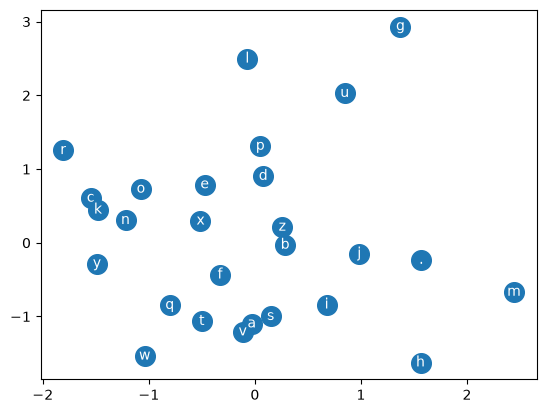

In [14]:
# visualise the character embeddings - only for when we do the 2 dimensional embeddings

# plt.figure((8,8))
plt.scatter(C[:, 0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), i_to_s[i], ha='center', va='center', color='white')

# some interesting obs
# - vowels get clustered together, the model recognises they are often interchangeable
# - some random characters get shunned - the model knows that q, g and . are special characters and cant just slot in anywhere


# Training loop

In [15]:
# create the dataset, now we have 228146 datapoints
# implement test and training splits
def build_dataset(words):
    block_size = 4
    X, Y = [], []

    for w in words:
        context = [0] * block_size
        for ch in w+'.':
            ix = s_to_i[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words)) # set first split point for train vs test/val
n2 = int(0.9*len(words)) # second split point for  test vs val

# create the datasets
X_train, Y_train = build_dataset(words[:n1])
X_val, Y_val = build_dataset(words[n1:n2])
X_test, Y_test = build_dataset(words[n2:])

In [16]:
# initialise
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g, requires_grad=True)
W1 = torch.ones((40, 200), requires_grad=True)
b1 = torch.randn(200, generator=g, requires_grad=True)
W2 = torch.ones((200, 27), requires_grad=True)
b2 = torch.randn(27, generator=g, requires_grad=True)
params = [C, W1, b1, W2, b2]

In [ ]:

# loop
for k in range(100000):

    # set up minibatching
    batch_size = 50
    ix = torch.randint(0, X_train.shape[0], (batch_size, )) # generate n integers from 0 to the length of X to give us the index that will make up our batches for training

    # forward
    emb = C[X_train[ix]]
    hidden_activation = torch.tanh(emb.view(-1, 40) @ W1 + b1)
    logits = hidden_activation @ W2 + b2
    loss = F.cross_entropy(logits, Y_train[ix])
    print(loss.item())
    
    # backward
    for p in params: # flush
        p.grad = None
    loss.backward()

    # gradient descent
    learning_rate = 0.01
    for p in params:
        p.data += -learning_rate * p.grad

In [20]:
# evaluate on train, val and test
for x, y in [(X_train, Y_train), (X_val, Y_val)]: 
    emb = C[x]
    hidden_activation = torch.tanh(emb.view(-1, 40) @ W1 + b1)
    logits = hidden_activation @ W2 + b2
    loss = F.cross_entropy(logits, y)
    print(loss.item())

4.3981828689575195
4.396291732788086


In [21]:
# what are some possible hyperparameters we can tune
# - embedding dimension size
# - size of hidden layer
# - number of characters to feed in to the model
# - training batch size
# - number of training iterations
# - learning rate config

In [22]:
# sample from the model
g = torch.Generator().manual_seed(2147483647+2)
for  _ in range(20):
    out = []
    context = [0] * 4 # start with '...'
    while True:
        emb = C[torch.tensor(context)] # get the embeddings for the 3 input characters
        h = torch.tanh(emb.view(1, -1) @ W1 + b1) # flatten the embedding matrix and multiply with weights, add bias and then tanh
        logits = h @ W2 + b2 # pass this onto the output layer
        probs = F.softmax(logits, dim=1) # take softmax to get probs, instead of manually taking exp and sum dividing
        ix = torch.multinomial(probs, num_samples=1, generator=g).item() # randomly sample an index using the probabilities
        context = context[1:] + [ix] # slide the context -> chop off the first ., replace the end with the new index so it stays 3 chars
        if ix == 0:
            break
        else:
            out.append(ix)
    print(''.join(i_to_s[i] for i in out))



vvcuok
uufuvvtovggstgfuvjvuvxvuguvvmvvvokpnfvovnougvfvudupfvtkurtyguuvoqup
vkouv
uovdvvsavvtbvpcvvscvvmvfxuutxfuuvuouuuyiuugxvfvppogukuvvvvvvvvksuvvouutuuvovalvvmugtuvovvdcaavuorvvvtscpuffcjcdvuhvvvvvgffkvvovvuuryyuooucvounvvc
vuuvfvaucgvvudibovftvruauvusuwrvo
dvvpufmuvsugmbuuvt
vubmrwpfuvvtvruvvuvnarvfsguvuuopbvpfubpvodvffsggcs
rpupgvvvrosptxpupptzuvu
pkcbvvosovbvvfrfsfgsvuuduumvfuvvkvvxufvguvfuugutcuouuoofsvvvvvpvrufvapuuvpapvuvvrvvpfqummvubtdcpvvofpurugvurvuvucogokfotuku
fp
gvvvuvvvuvvfuuvvviyyvpuuuviuvpubyvpugxdukp
fvvvvvvgvuumvgkcuuvgapvibvuvyuuvcgcvvtueuvvvfouuvudvvupvkvuvvpovuuvufryif
vvyuufvovvvgucivpviuuvvcvfvrxsdykvcouskfgvu
psmvtvvvyvghujuvxvuuvruooprxyuvxvufvcvvusvvvvuxvkqqfvdvuvkguvosvyuuuukvdubupuvguvivoviuyvvbovvumuusgvvqvuuduruusfvvvfskuuvvuvfvfvvrrcuhovvutoufvvufvutq
spmubuvvvvqsvvutgvvgvvsfuuuuvgukvvpuvuvvravzvbvvuvvuuvrubivofcv
vanpfctorctsfkvduvvvsusupavggpuvpuyrpvguuvuuuupvfuvnvuquuatvvgpvvoauvt
dufcwfvvkouuuvuagviuopmuuuvxcuupuuugvputzuuhzvusapvvuvuuuufdumfmvypudn